# Week 10 - Clustering 1, K-Means
## Dataset: FEMA NFIP Claims

This week moves from supervised learning to clustering, starting with k-means. Every model so far learned to predict a label, such as whether a claim paid more than $50,000. Clustering has no label. It looks for groups of claims that sit close together in feature space, and the analyst has to decide whether those groups mean anything.

K-means places k cluster centers, assigns each claim to its nearest center, moves each center to the mean of its claims, and repeats until nothing changes. It minimizes inertia, the sum of squared Euclidean distances from each claim to its center. Because everything depends on distance, the choices that matter most are which features go in, how they are scaled, and how distance is measured. The number of clusters k also has to be chosen, here with the elbow method and the silhouette score.

The notebook clusters the NFIP claims in two ways. Part A clusters claim locations, to see whether k-means rediscovers the 2017 flood events without being told about them. Part B clusters claims by building and flood characteristics, to see whether there are natural types of claims and whether those types differ in how much they pay. Payouts are left out of both clusterings, so they can be used afterward to check what the clusters mean.

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, MinMaxScaler, normalize
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

warnings.filterwarnings('ignore', category=FutureWarning)

columns = ['yearOfLoss', 'amountPaidOnBuildingClaim', 'originalConstructionDate', 'ratedFloodZone',
           'buildingReplacementCost', 'totalBuildingInsuranceCoverage', 'waterDepth',
           'numberOfFloorsInTheInsuredBuilding', 'elevatedBuildingIndicator', 'primaryResidenceIndicator',
           'postFIRMConstructionIndicator', 'latitude', 'longitude', 'floodEvent']
df_raw = pd.read_csv('FimaNfipClaimsV2.csv', low_memory=False, usecols=columns)
df = df_raw[(df_raw['yearOfLoss'] == 2017) & (df_raw['amountPaidOnBuildingClaim'] >= 0)].copy()
print('2017 claims with a non-negative building payout:', len(df))

2017 claims with a non-negative building payout: 113398


### Data

The claims are the same 101,042 used in Weeks 4 to 9. FEMA's `floodEvent` field names the disaster behind most claims, with Hurricane Harvey alone accounting for 70% of them. It is used only to check the location clusters.

In [2]:
df['constructionYear'] = pd.to_datetime(df['originalConstructionDate'], errors='coerce').dt.year
zone_letter = df['ratedFloodZone'].astype(str).str.upper().str[0]
df['zoneA'] = (zone_letter == 'A').astype(int)
df['zoneV'] = (zone_letter == 'V').astype(int)
df['logReplacementCost'] = np.log10(df['buildingReplacementCost'].clip(lower=1))
df['logCoverage'] = np.log10(df['totalBuildingInsuranceCoverage'].clip(lower=1))
profile_features = ['waterDepth', 'logReplacementCost', 'logCoverage', 'numberOfFloorsInTheInsuredBuilding',
                    'elevatedBuildingIndicator', 'primaryResidenceIndicator', 'postFIRMConstructionIndicator',
                    'constructionYear', 'zoneA', 'zoneV']
data = df.dropna(subset=profile_features + ['latitude', 'longitude']).copy()
data = data[data['constructionYear'].between(1800, 2017)].reset_index(drop=True)
data['largeClaim'] = (data['amountPaidOnBuildingClaim'] > 50000).astype(int)
data['event'] = data['floodEvent'].fillna('Not named')
print('Claims used:', len(data))
print(data['event'].value_counts().head(6).to_string())

Claims used: 101042
event
Hurricane Harvey                70463
Hurricane Irma                  19079
Not named                        8929
Late spring severe storms        1508
Greater New Orleans Flooding      636
Hurricane Maria                   427


## Part A - Clustering claim locations

### Choosing k

The redacted claims give latitude and longitude rounded to 0.1 degree, so the 101,042 claims sit at only a few thousand distinct locations. K-means is run on those locations, weighted by the number of claims at each, after converting latitude and longitude to kilometers east and north so that a kilometer counts the same in every direction. The next cell tries k from 2 to 12 and records the inertia (for the elbow method), the silhouette score on a random 10,000 claims, and the adjusted Rand index (ARI) between the clusters and FEMA's flood event names.

The silhouette of a claim compares its average distance to the other claims in its cluster (a) with its average distance to the claims in the nearest other cluster (b), as (b - a) / max(a, b), so it runs from -1 to 1 and values near 1 mean tight, well-separated clusters. The ARI measures how well two groupings agree, where 0 is what chance would give and 1 means they are identical.

Distinct locations (coordinates are rounded to 0.1 degree): 3580
Share of claims in the 100 busiest locations: 0.716


 k  Inertia (million km squared)  Silhouette (10,000 claims)  ARI with flood event
 2                     22670.434                       0.758                 0.819
 3                     13649.702                       0.771                 0.843
 4                     10169.325                       0.798                 0.890
 5                      6901.467                       0.796                 0.864
 6                      5622.124                       0.809                 0.872
 7                      4616.083                       0.815                 0.876
 8                      4062.013                       0.736                 0.795
 9                      3469.541                       0.655                 0.662
10                      3040.719                       0.736                 0.795
11                      2525.332                       0.746                 0.833
12                      2073.799                       0.748                 0.834
k wi

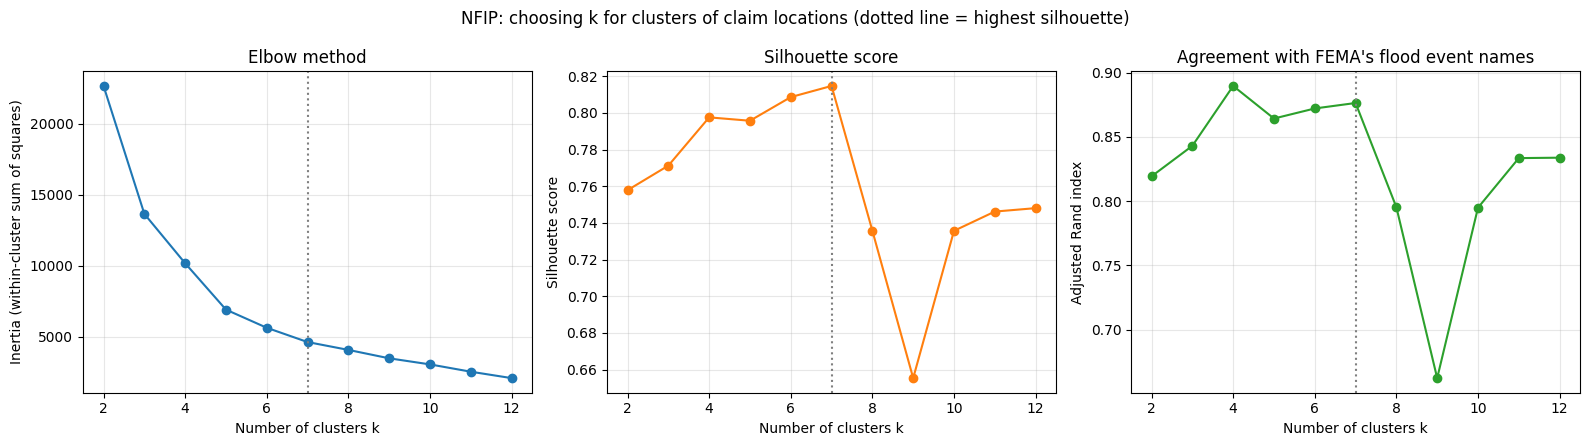

In [3]:
cells = (data.groupby(['latitude', 'longitude']).size().rename('claims').reset_index())
print('Distinct locations (coordinates are rounded to 0.1 degree):', len(cells))
print(f'Share of claims in the 100 busiest locations: {cells["claims"].nlargest(100).sum() / len(data):.3f}')


def to_km(lat, lon):
    """Project latitude and longitude to kilometers, so east-west and north-south distances match."""
    return np.c_[lon * 111.32 * np.cos(np.radians(lat)), lat * 110.57]


cell_km = to_km(cells['latitude'], cells['longitude'])
cell_deg = cells[['longitude', 'latitude']].values
claim_cell = data.merge(cells.reset_index()[['latitude', 'longitude', 'index']], on=['latitude', 'longitude'], how='left')['index'].values
sample = np.random.RandomState(0).choice(len(data), 10000, replace=False)

geo_rows = []
for k in range(2, 13):
    km_model = KMeans(n_clusters=k, n_init=10, random_state=0).fit(cell_km, sample_weight=cells['claims'])
    claim_labels = km_model.labels_[claim_cell]
    geo_rows.append({'k': k, 'Inertia (million km squared)': km_model.inertia_ / 1e6,
                     'Silhouette (10,000 claims)': silhouette_score(cell_km[claim_cell[sample]], claim_labels[sample]),
                     'ARI with flood event': adjusted_rand_score(data['event'], claim_labels)})
geo_table = pd.DataFrame(geo_rows)
k_geo = int(geo_table.loc[geo_table['Silhouette (10,000 claims)'].idxmax(), 'k'])
print(geo_table.round(3).to_string(index=False))
print('k with the highest silhouette:', k_geo)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].plot(geo_table['k'], geo_table['Inertia (million km squared)'], marker='o')
axes[0].set_ylabel('Inertia (within-cluster sum of squares)')
axes[0].set_title('Elbow method')
axes[1].plot(geo_table['k'], geo_table['Silhouette (10,000 claims)'], marker='o', color='C1')
axes[1].set_ylabel('Silhouette score')
axes[1].set_title('Silhouette score')
axes[2].plot(geo_table['k'], geo_table['ARI with flood event'], marker='o', color='C2')
axes[2].set_ylabel('Adjusted Rand index')
axes[2].set_title("Agreement with FEMA's flood event names")
for ax in axes:
    ax.axvline(k_geo, color='gray', linestyle=':')
    ax.set_xlabel('Number of clusters k')
    ax.grid(alpha=0.3)
fig.suptitle('NFIP: choosing k for clusters of claim locations (dotted line = highest silhouette)')
plt.tight_layout()
plt.show()

The 101,042 claims sit at 3,580 distinct locations, and the 100 busiest locations hold 71.6% of all claims. The inertia falls steeply up to k = 5 and then flattens, and the silhouette is high throughout (0.74 to 0.82, apart from a dip to 0.66 at k = 9) and peaks at k = 7 (0.815), so the locations have strong cluster structure. Agreement with FEMA's flood event names is also high, 0.876 at k = 7, even though k-means never saw them. Past k = 7 both scores drop, because the extra clusters start splitting a single disaster such as Harvey into pieces.

### The location clusters on a map

The next cell fits k-means with k = 7, compares it with the same clustering done on raw degrees, and profiles each cluster by its main flood event and its payouts.

Kilometers per degree of longitude at 18, 30, and 45 degrees north: 106, 96, 79
ARI between clusters on kilometers and on raw degrees: 0.978
ARI with flood event, kilometers: 0.876 | raw degrees: 0.864

            claims  latitude  longitude  largeClaimShare  medianPayout                  mainEvent  mainEventShare
geoCluster                                                                                                       
0            72886    29.713    -95.142            0.640     71511.905           Hurricane Harvey           0.967
2            11929    25.820    -81.360            0.258     17169.890             Hurricane Irma           0.891
1             8912    30.712    -81.211            0.306     22982.475             Hurricane Irma           0.942
3             2864    41.332    -81.312            0.096      9343.365                  Not named           0.999
6             2777    37.566    -93.407            0.242     20711.900  Late spring severe storms           0.542

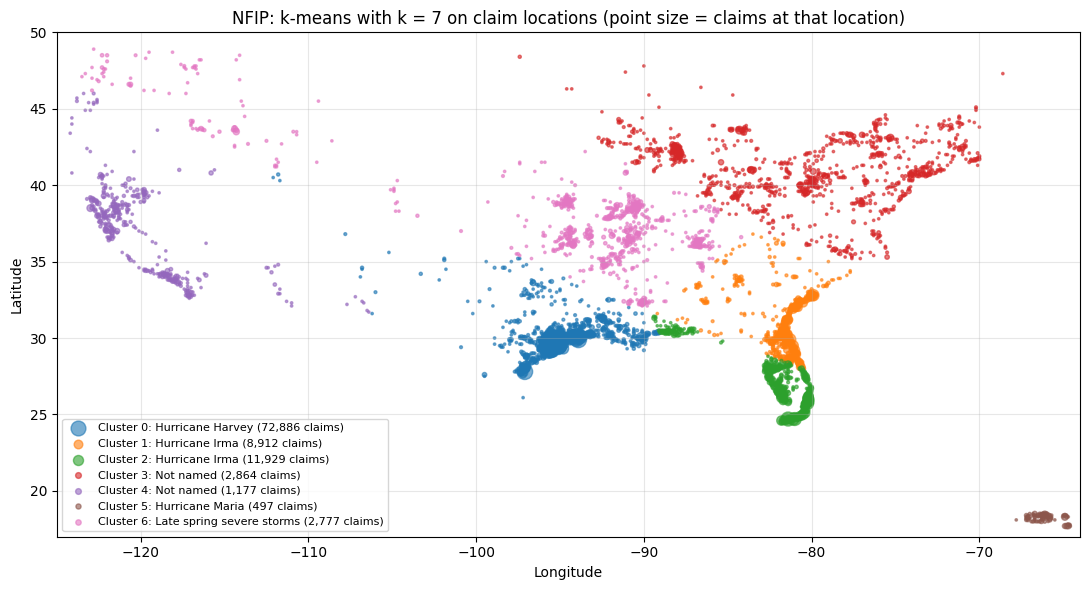

Locations outside the map area: 9


In [4]:
geo_km = KMeans(n_clusters=k_geo, n_init=10, random_state=0).fit(cell_km, sample_weight=cells['claims'])
geo_deg = KMeans(n_clusters=k_geo, n_init=10, random_state=0).fit(cell_deg, sample_weight=cells['claims'])
data['geoCluster'] = geo_km.labels_[claim_cell]
deg_labels = geo_deg.labels_[claim_cell]
print(f'Kilometers per degree of longitude at 18, 30, and 45 degrees north: '
      f'{", ".join(f"{111.32 * np.cos(np.radians(lat)):.0f}" for lat in [18, 30, 45])}')
print(f'ARI between clusters on kilometers and on raw degrees: {adjusted_rand_score(data["geoCluster"], deg_labels):.3f}')
print(f'ARI with flood event, kilometers: {adjusted_rand_score(data["event"], data["geoCluster"]):.3f}'
      f' | raw degrees: {adjusted_rand_score(data["event"], deg_labels):.3f}')

profile = data.groupby('geoCluster').agg(claims=('largeClaim', 'size'), latitude=('latitude', 'mean'),
                                         longitude=('longitude', 'mean'), largeClaimShare=('largeClaim', 'mean'),
                                         medianPayout=('amountPaidOnBuildingClaim', 'median'),
                                         mainEvent=('event', lambda s: s.value_counts().index[0]),
                                         mainEventShare=('event', lambda s: s.value_counts(normalize=True).iloc[0]))
print()
print(profile.sort_values('claims', ascending=False).round(3).to_string())

fig, ax = plt.subplots(figsize=(11, 6))
for c in range(k_geo):
    pts = cells[geo_km.labels_ == c]
    ax.scatter(pts['longitude'], pts['latitude'], s=np.sqrt(pts['claims']) * 3, alpha=0.6,
               label=f'Cluster {c}: {profile.loc[c, "mainEvent"]} ({profile.loc[c, "claims"]:,} claims)')
ax.set_xlim(-125, -64)
ax.set_ylim(17, 50)
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_title(f'NFIP: k-means with k = {k_geo} on claim locations (point size = claims at that location)')
ax.legend(fontsize=8, loc='lower left')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print('Locations outside the map area:', int(((cells['longitude'] < -125) | (cells['longitude'] > -64) | (cells['latitude'] < 17)).sum()))

The seven clusters are the disasters of 2017. Cluster 0 is Hurricane Harvey around Houston (72,886 claims, 96.7% of them Harvey claims). Clusters 1 and 2 split Hurricane Irma into northern Florida with Georgia and South Carolina (8,912 claims) and southern Florida (11,929 claims). Cluster 5 is Hurricane Maria in Puerto Rico (497 claims), and cluster 6 is the late spring storms in Missouri and the Mississippi valley (2,777 claims). The remaining two gather scattered claims with no event name, one in the Northeast and Great Lakes and one on the West Coast.

The payouts differ sharply. In the Harvey cluster 64% of claims paid more than $50,000, with a median payout of $71,512, against 26% to 31% for the two Irma clusters and 10% in the Northeast. This is the same storm effect that longitude captured in every model since Week 4.

Measuring distance in kilometers or in raw degrees hardly matters here (ARI 0.978 between the two). The disasters are compact and far apart, so the different length of a degree of longitude at 18 and 45 degrees north (106 and 79 km) does not move any boundary that matters.

## Part B - Clustering claim profiles

### Feature scaling

The second clustering uses ten building and flood features, water depth (as the log of 1 plus depth), log replacement cost and coverage, the number of floors, construction year, and indicators for elevated buildings, primary residences, post-FIRM construction, and A and V flood zones. Location is left out. The next cell clusters these features with k = 4 under no scaling, min-max scaling, and standardization, and reports which feature the clusters split on most, measured as the share of that feature's variance explained by the clusters.

In [5]:
X_prof = data[profile_features].copy()
X_prof['waterDepth'] = np.log1p(X_prof['waterDepth'].clip(lower=0))
print('Water depth enters as log(1 + depth), since it runs to', int(data['waterDepth'].max()), 'with a median of',
      data['waterDepth'].median())

scaling_rows, label_sets = [], {}
for name, Z in [('No scaling', X_prof.values), ('Min-max', MinMaxScaler().fit_transform(X_prof)),
                ('Standardized', StandardScaler().fit_transform(X_prof))]:
    labels = KMeans(n_clusters=4, n_init=10, random_state=0).fit_predict(Z)
    label_sets[name] = labels
    # Share of each feature's variance explained by the clusters (1 = the clusters split on it completely)
    explained = pd.Series({f: 1 - pd.Series(Z[:, i]).groupby(labels).var().mul(np.bincount(labels)).sum()
                           / (Z[:, i].var() * len(Z)) for i, f in enumerate(profile_features)})
    rates = data['largeClaim'].groupby(labels).mean()
    scaling_rows.append({'Scaling': name, 'Silhouette (k = 4)': silhouette_score(Z, labels, sample_size=10000, random_state=0),
                         'Feature the clusters split on most': explained.idxmax(),
                         'Its variance explained': explained.max(),
                         'Features with over 30% explained': int((explained > 0.3).sum()),
                         'Large-claim share, lowest to highest cluster': f'{rates.min():.2f} to {rates.max():.2f}'})
print()
print(pd.DataFrame(scaling_rows).round(3).to_string(index=False))

Water depth enters as log(1 + depth), since it runs to 610 with a median of 1.0



     Scaling  Silhouette (k = 4) Feature the clusters split on most  Its variance explained  Features with over 30% explained Large-claim share, lowest to highest cluster
  No scaling               0.561                   constructionYear                   0.883                                 2                                 0.23 to 0.55
     Min-max               0.469      postFIRMConstructionIndicator                   1.000                                 3                                 0.48 to 0.62
Standardized               0.210                              zoneV                   1.000                                 4                                 0.28 to 0.58


Each scaling produces a different clustering, and the silhouette score cannot choose between them.

- **No scaling.** Construction year dominates (88.3% of its variance explained), since its spread in years dwarfs every other feature, and the clusters are essentially construction eras. That gives the highest silhouette (0.561), but only because the clusters are slices of one feature.
- **Min-max scaling.** Every feature is put on 0 to 1, so the 0/1 indicators keep their full range while the continuous features are squeezed by their extremes, and the clusters split entirely on post-FIRM construction.
- **Standardization.** Every feature counts, and four features have more than 30% of their variance explained, but the silhouette falls to 0.210.

Standardizing has its own bias. A rare indicator such as the V zone (about 1% of claims) gets a standardized value near 10 for the claims that have it, so k-means can isolate those claims in a cluster of their own, which is what happened here. Standardization is used from here on, since it is the only choice that lets all ten features shape the clusters, and its clusters already separate large claims well (28% to 58% across the four clusters) without having seen any payout.

### Choosing k with the elbow and the silhouette

The next cell runs k-means for k from 2 to 12 on the standardized profiles. The elbow point is found as the k whose scaled inertia lies farthest below the straight line from k = 2 to k = 12, and the silhouette is computed on 10,000 claims.

 k    Inertia  Silhouette  Distance from the line
 2 843616.733       0.211                   0.000
 3 758063.880       0.206                   0.084
 4 677504.535       0.210                   0.157
 5 605692.081       0.226                   0.211
 6 570939.492       0.208                   0.186
 7 522753.265       0.219                   0.189
 8 487508.098       0.231                   0.165
 9 452580.780       0.240                   0.140
10 420521.909       0.250                   0.109
11 392909.842       0.267                   0.068
12 378019.686       0.269                   0.000
Elbow point: 5 | highest silhouette: 12


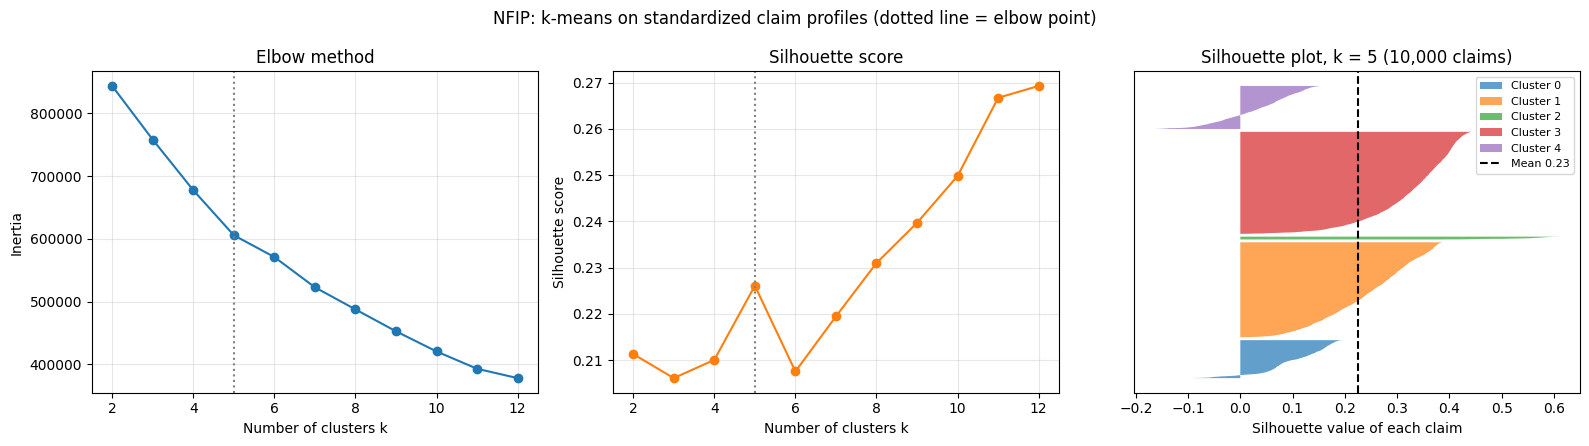

In [6]:
Z_prof = StandardScaler().fit_transform(X_prof)
prof_rows = []
for k in range(2, 13):
    m = KMeans(n_clusters=k, n_init=10, random_state=0).fit(Z_prof)
    prof_rows.append({'k': k, 'Inertia': m.inertia_,
                      'Silhouette': silhouette_score(Z_prof, m.labels_, sample_size=10000, random_state=0)})
prof_table = pd.DataFrame(prof_rows)
# Elbow point, the k farthest from the straight line joining the first and last points of the scaled inertia curve
x = (prof_table['k'] - 2) / 10
yv = (prof_table['Inertia'] - prof_table['Inertia'].min()) / (prof_table['Inertia'].max() - prof_table['Inertia'].min())
prof_table['Distance from the line'] = (1 - x) - yv
k_prof = int(prof_table.loc[prof_table['Distance from the line'].idxmax(), 'k'])
print(prof_table.round(3).to_string(index=False))
print('Elbow point:', k_prof, '| highest silhouette:', int(prof_table.loc[prof_table['Silhouette'].idxmax(), 'k']))

prof_model = KMeans(n_clusters=k_prof, n_init=10, random_state=0).fit(Z_prof)
data['profileCluster'] = prof_model.labels_
sil = silhouette_samples(Z_prof[sample], prof_model.labels_[sample])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].plot(prof_table['k'], prof_table['Inertia'], marker='o')
axes[0].set_title('Elbow method')
axes[0].set_ylabel('Inertia')
axes[1].plot(prof_table['k'], prof_table['Silhouette'], marker='o', color='C1')
axes[1].set_title('Silhouette score')
axes[1].set_ylabel('Silhouette score')
for ax in axes[:2]:
    ax.axvline(k_prof, color='gray', linestyle=':')
    ax.set_xlabel('Number of clusters k')
    ax.grid(alpha=0.3)
y0 = 0
for c in range(k_prof):
    vals = np.sort(sil[prof_model.labels_[sample] == c])
    axes[2].fill_betweenx(np.arange(y0, y0 + len(vals)), 0, vals, alpha=0.7, label=f'Cluster {c}')
    y0 += len(vals) + 100
axes[2].axvline(sil.mean(), color='black', linestyle='--', label=f'Mean {sil.mean():.2f}')
axes[2].set_xlabel('Silhouette value of each claim')
axes[2].set_yticks([])
axes[2].set_title(f'Silhouette plot, k = {k_prof} (10,000 claims)')
axes[2].legend(fontsize=8)
fig.suptitle('NFIP: k-means on standardized claim profiles (dotted line = elbow point)')
plt.tight_layout()
plt.show()

Unlike the locations, the claim profiles have weak cluster structure. The inertia curve bends gradually, with the elbow at k = 5, and the silhouette stays between 0.21 and 0.27. It has a local peak at k = 5 (0.226) and then climbs again past k = 8, because many small clusters can each pick off one combination of the 0/1 indicators. The silhouette plot at k = 5 shows a mean of 0.23, one small cluster with values up to about 0.6 (the V zone claims), and two clusters with many negative values. I used k = 5, where the elbow and a local silhouette peak agree.

### What the claim clusters mean

The next cell profiles the five clusters with the features used to form them and with three things that were not used, the share of claims over $50,000, the median payout, and the share of Harvey claims.

In [7]:
summary = data.groupby('profileCluster').agg(
    claims=('largeClaim', 'size'), waterDepth=('waterDepth', 'median'),
    replacementCost=('buildingReplacementCost', 'median'), constructionYear=('constructionYear', 'median'),
    elevated=('elevatedBuildingIndicator', 'mean'), zoneA=('zoneA', 'mean'), zoneV=('zoneV', 'mean'),
    primary=('primaryResidenceIndicator', 'mean'), postFIRM=('postFIRMConstructionIndicator', 'mean'),
    largeClaimShare=('largeClaim', 'mean'), medianPayout=('amountPaidOnBuildingClaim', 'median'),
    harveyShare=('event', lambda s: (s == 'Hurricane Harvey').mean()))
print('Cluster profiles (payout, large-claim share, and Harvey share were not used to form the clusters)')
print(summary.round(2).to_string())
print(f'\nOverall large-claim share: {data["largeClaim"].mean():.3f}')
print(f'ARI between profile clusters and location clusters: {adjusted_rand_score(data["profileCluster"], data["geoCluster"]):.3f}')

Cluster profiles (payout, large-claim share, and Harvey share were not used to form the clusters)
                claims  waterDepth  replacementCost  constructionYear  elevated  zoneA  zoneV  primary  postFIRM  largeClaimShare  medianPayout  harveyShare
profileCluster                                                                                                                                              
0                13929         1.0         223980.0            1969.0      0.04   0.74    0.0     0.00      0.11             0.47      47000.00         0.55
1                34780         1.0         280072.0            1994.0      0.00   0.41    0.0     0.84      1.00             0.66      77654.20         0.85
2                 1093         1.0         273910.0            1974.0      0.59   0.00    1.0     0.44      0.44             0.28      18236.31         0.13
3                35817         1.0         209572.0            1968.0      0.01   0.54    0.0     1.00      0.00     

The five clusters are recognizable kinds of flood claims.

- **Cluster 1** (34,780 claims) is newer homes, built around 1994, all post-FIRM, none elevated, and mostly primary residences (84%). 66% paid more than $50,000, the highest share, with a median payout of $77,654.
- **Cluster 3** (35,817 claims) is older primary homes, built around 1968 and pre-FIRM, with 58% large claims.
- **Cluster 0** (13,929 claims) is older buildings that are not primary residences, such as rentals and second homes, with 47% large claims.
- **Cluster 4** (15,423 claims) is elevated buildings (99%), with only 21% large claims and a median payout of $12,919.
- **Cluster 2** (1,093 claims) is coastal V-zone buildings, with 28% large claims.

Elevation separates payouts more than anything else, which matches its importance in every model since Week 1. The order of clusters 1 and 3 is not a building effect. Newer homes had the highest share of large claims because 85% of them were Harvey claims, against 74% for cluster 3 and 41% for the elevated cluster, and Harvey claims paid more across the board (Part A). The profile clusters and the location clusters are almost unrelated (ARI 0.095), so the two clusterings describe different things, what kind of building flooded and which storm flooded it.

### Distance metrics

K-means always minimizes squared Euclidean distance, but the same clusters can be scored with other metrics, and k-means can be adapted to cosine distance by scaling each claim's feature vector to length 1 before clustering (spherical k-means). The next cell does both.

In [8]:
labels = prof_model.labels_
metric_rows = [{'Silhouette computed with': m,
                'Score (same k-means clusters)': silhouette_score(Z_prof, labels, metric=m, sample_size=10000, random_state=0)}
               for m in ['euclidean', 'manhattan', 'cosine']]
print(pd.DataFrame(metric_rows).round(3).to_string(index=False))

# Cosine distance version, k-means on rows scaled to length 1 (spherical k-means), which groups claims by direction
Z_unit = normalize(Z_prof)
cos_labels = KMeans(n_clusters=k_prof, n_init=10, random_state=0).fit_predict(Z_unit)
print(f'\nARI between Euclidean k-means and cosine (spherical) k-means: {adjusted_rand_score(labels, cos_labels):.3f}')
for name, lab in [('Euclidean k-means', labels), ('Cosine (spherical) k-means', cos_labels)]:
    rates = data['largeClaim'].groupby(lab).mean()
    print(f'{name:28s} cluster sizes {sorted(np.bincount(lab).tolist(), reverse=True)} | large-claim share {rates.min():.2f} to {rates.max():.2f}')

Silhouette computed with  Score (same k-means clusters)
               euclidean                          0.226
               manhattan                          0.289
                  cosine                          0.373



ARI between Euclidean k-means and cosine (spherical) k-means: 0.684
Euclidean k-means            cluster sizes [35817, 34780, 15423, 13929, 1093] | large-claim share 0.21 to 0.66
Cosine (spherical) k-means   cluster sizes [29256, 19359, 19349, 17003, 16075] | large-claim share 0.21 to 0.67


The same five clusters score 0.226 with Euclidean distance, 0.289 with Manhattan distance, and 0.373 with cosine distance. The higher scores do not mean better clusters, only a different idea of similarity. Manhattan distance gives less weight than Euclidean to one large difference, such as the V zone indicator's, and cosine distance compares only the pattern of a claim's features. Spherical k-means, which clusters on direction, agrees moderately with the Euclidean clustering (ARI 0.684) but has far more even cluster sizes (16,075 to 29,256 claims, against 1,093 to 35,817), because it no longer isolates the rare V zone claims by their distance from the center. Its clusters separate large claims equally well (21% to 67%).

### Stability

A clustering that changes completely when the random start or the sample changes cannot be trusted. The next cell compares 10 runs with a single random start each. It then clusters two random halves of the data separately and checks whether the half-A centers label half B the same way half B's own clustering does.

In [9]:
pairs = []
for name, Z, k, weight in [('Locations', cell_km, k_geo, cells['claims'].values), ('Claim profiles', Z_prof, k_prof, None)]:
    runs = [KMeans(n_clusters=k, n_init=1, random_state=s).fit(Z, sample_weight=weight).labels_ for s in range(10)]
    seed_ari = [adjusted_rand_score(runs[i], runs[j]) for i in range(10) for j in range(i + 1, 10)]
    inertias = [KMeans(n_clusters=k, n_init=1, random_state=s).fit(Z, sample_weight=weight).inertia_ for s in range(10)]
    # Split-half check, cluster each half, then label half B with the half-A centers and compare
    half = np.random.RandomState(1).rand(len(Z)) < 0.5
    wa = None if weight is None else weight[half]
    wb = None if weight is None else weight[~half]
    model_a = KMeans(n_clusters=k, n_init=10, random_state=0).fit(Z[half], sample_weight=wa)
    model_b = KMeans(n_clusters=k, n_init=10, random_state=0).fit(Z[~half], sample_weight=wb)
    pairs.append({'Clustering': name, 'k': k,
                  'ARI between single-start runs, min': min(seed_ari), 'median': np.median(seed_ari),
                  'Inertia spread across starts': (max(inertias) - min(inertias)) / min(inertias),
                  'Split-half ARI': adjusted_rand_score(model_a.predict(Z[~half]), model_b.labels_)})
print(pd.DataFrame(pairs).round(3).to_string(index=False))

    Clustering  k  ARI between single-start runs, min  median  Inertia spread across starts  Split-half ARI
     Locations  7                               0.716   0.845                         0.129           0.978
Claim profiles  5                               0.396   0.642                         0.115           0.876


The location clusters are very stable. Single-start runs agree with a median ARI of 0.845, and the two halves agree at 0.978. The claim profile clusters depend more on the random start (median ARI 0.642, minimum 0.396, with inertia differing by up to 11.5% between starts), so the 10 starts used throughout matter, but with them the halves agree well (0.876).

## Discussion

### Overfitting

In clustering, overfitting means finding groups that describe this particular sample instead of structure that would appear again. Three checks guarded against it. The number of clusters was chosen with the elbow method and the silhouette score, which stop rewarding extra centers once they no longer separate the data. Every fit used 10 random starts and kept the best, since single starts landed on noticeably different partitions of the claim profiles. And the split-half check showed both final clusterings reappearing in independent halves of the data (ARI 0.978 for locations and 0.876 for profiles). The outside checks also count against overfitting. The location clusters match FEMA's event names (ARI 0.876), and the profile clusters separate large claims from 21% to 66%, though neither the event names nor the payouts were used to form them.

### Metrics and hyperparameter tuning

The metrics were inertia (the within-cluster sum of squared distances, used for the elbow method), the silhouette score (how much closer each claim is to its own cluster than to the next, from -1 to 1), and the adjusted Rand index (agreement between two groupings beyond chance). The main hyperparameter is k, chosen at 7 for locations, where the silhouette peaked at 0.815, and at 5 for profiles, where the elbow and a local silhouette peak agreed. The other choices act like hyperparameters. Weighting each location by its number of claims makes the clusters follow claims instead of places, the kilometer projection makes distance mean the same in every direction, standardization decides how much each building feature counts, and `n_init=10` sets the number of random starts. The silhouette cannot compare different scalings or metrics, since it rose to 0.561 without scaling only because one feature took over.

### Expected or unexpected

I expected the location clusters to follow the hurricanes, but not to match FEMA's event names this closely (ARI 0.876) or to split Irma into two clusters by region. I did not expect the profile clusters to separate large claims so well (21% to 66%) given their weak silhouette (0.226), which shows that weakly separated clusters can still be useful. The way standardization handled rare indicators was also unexpected, since the V zone claims became their own cluster because their standardized values were extreme, not because they were similar in many ways.

### How EDA helped

EDA shaped every feature here. Water depth runs to 610 with a median of 1, so it enters as the log of 1 plus depth, and replacement cost and coverage enter as logs, since raw values would let a few extreme claims set the distances. The Week 4 finding that one claim in Guam stretched the longitude range is a reason min-max scaling was a poor choice, and the coordinate rounding found in Week 8 is why the location clustering runs on 3,580 weighted locations. The importance of elevation in every earlier model is why the elevated cluster's low payouts were expected. EDA did not suggest that claim profiles lack natural groups. That only showed up in the silhouette scores.

### External sources

- Arthur, D., & Vassilvitskii, S. (2007). k-means++: The advantages of careful seeding. *Proceedings of the Eighteenth Annual ACM-SIAM Symposium on Discrete Algorithms*, 1027-1035.
- Rousseeuw, P. J. (1987). Silhouettes: A graphical aid to the interpretation and validation of cluster analysis. *Journal of Computational and Applied Mathematics*, 20, 53-65.
- scikit-learn example, "Selecting the number of clusters with silhouette analysis on KMeans clustering": https://scikit-learn.org/stable/auto_examples/cluster/plot_kmeans_silhouette_analysis.html
- scikit-learn User Guide, "Clustering," the sections on k-means and on clustering performance evaluation: https://scikit-learn.org/stable/modules/clustering.html

### Conclusions

K-means rediscovers the 2017 flood disasters from claim locations alone, with seven well-separated clusters (silhouette 0.815) that match FEMA's event names (ARI 0.876), and Harvey's cluster stands out with 64% of claims over $50,000. Claim profiles have no strong natural groups (silhouette 0.226), but five reproducible clusters still separate large claims from 21% (elevated buildings) to 66% (newer homes, mostly in Harvey). Feature scaling decided what the clusters were about, from construction year without scaling to post-FIRM status with min-max scaling and a mix of features with standardization.

For Milestone Two and the Capstone, the two clusterings support the main finding of the earlier weeks from a different angle. Which storm flooded a building matters as much as the building itself, and elevation is the building feature that matters most. The location clusters could also replace raw longitude in the supervised models as a cleaner way to encode the storm.